First 5 Rows of Dataset
          Location      Time Severity  Latitude  Longitude
0          MG Road  08:30:00     High   12.9756    77.6050
1       Whitefield  21:15:00   Medium   12.9698    77.7500
2      Indiranagar  18:45:00     High   12.9784    77.6408
3  Electronic City  09:20:00      Low   12.8399    77.6770
4           Hebbal  22:10:00     High   13.0358    77.5970


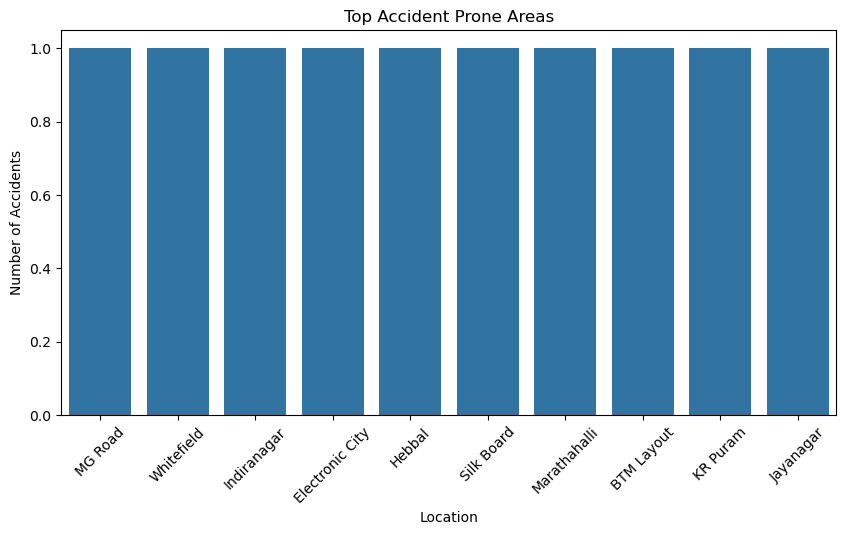

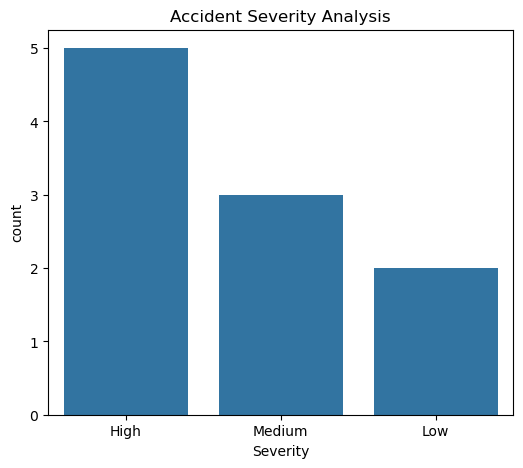

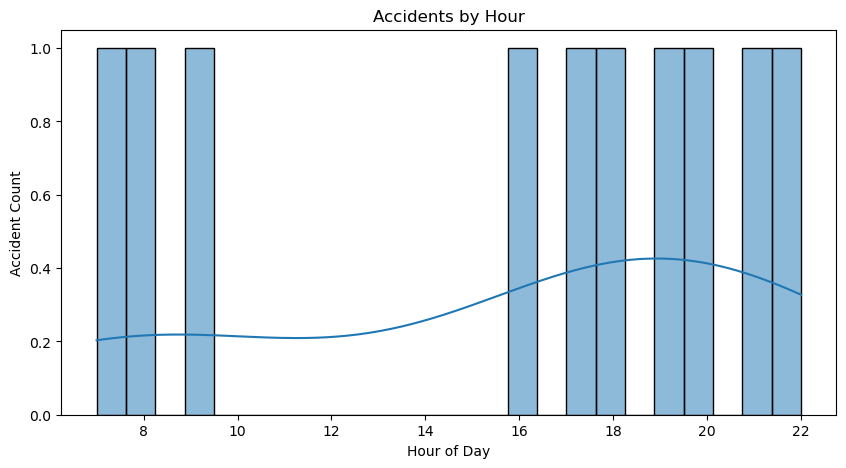

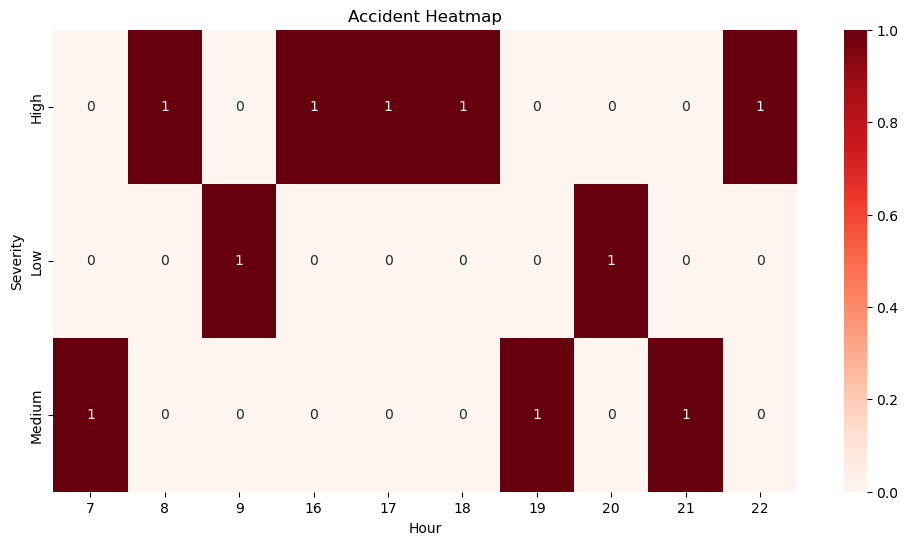

Map has been saved as accident_prone_areas_map.html

Top Accident Prone Areas
Location
MG Road            1
Whitefield         1
Indiranagar        1
Electronic City    1
Hebbal             1
Silk Board         1
Marathahalli       1
BTM Layout         1
KR Puram           1
Jayanagar          1
Name: count, dtype: int64


In [3]:
# Accident Prone Area Detection System
# ------------------------------------

# Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium

# Load Dataset
# Replace 'accident_data.csv' with your dataset file name
data = pd.read_csv("accident_data.csv")
("C:/Users/Deepika/Desktop/accident_data.csv")

# Display First 5 Rows
print("First 5 Rows of Dataset")
print(data.head())

# ------------------------------------
# Data Cleaning
# ------------------------------------

# Remove null values
data = data.dropna()

# Convert Time Column to Datetime Format
data['Time'] = pd.to_datetime(data['Time'], format='%H:%M:%S')

# Extract Hour
data['Hour'] = data['Time'].dt.hour

# ------------------------------------
# Accident Count by Area
# ------------------------------------

plt.figure(figsize=(10,5))

top_locations = data['Location'].value_counts().head(10)

sns.barplot(
    x=top_locations.index,
    y=top_locations.values
)

plt.title("Top Accident Prone Areas")
plt.xlabel("Location")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=45)

plt.show()

# ------------------------------------
# Severity Analysis
# ------------------------------------

plt.figure(figsize=(6,5))

sns.countplot(
    x='Severity',
    data=data
)

plt.title("Accident Severity Analysis")

plt.show()

# ------------------------------------
# Time-wise Accident Analysis
# ------------------------------------

plt.figure(figsize=(10,5))

sns.histplot(
    data['Hour'],
    bins=24,
    kde=True
)

plt.title("Accidents by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Accident Count")

plt.show()

# ------------------------------------
# Heatmap
# ------------------------------------

pivot_table = data.pivot_table(
    index='Severity',
    columns='Hour',
    aggfunc='size',
    fill_value=0
)

plt.figure(figsize=(12,6))

sns.heatmap(
    pivot_table,
    cmap='Reds',
    annot=True
)

plt.title("Accident Heatmap")

plt.show()

# ------------------------------------
# Folium Map Visualization
# ------------------------------------

# Create Base Map
m = folium.Map(
    location=[12.9716, 77.5946],   # Example: Bangalore Coordinates
    zoom_start=10
)

# Add Markers
for index, row in data.iterrows():

    folium.Marker(
        location=[row['Latitude'], row['Longitude']],
        popup=f"Location: {row['Location']}<br>Severity: {row['Severity']}",
        icon=folium.Icon(color='red')
    ).add_to(m)

# Save Map
m.save("accident_prone_areas_map.html")

print("Map has been saved as accident_prone_areas_map.html")

# ------------------------------------
# Detect Top Accident Prone Areas
# ------------------------------------

print("\nTop Accident Prone Areas")

print(data['Location'].value_counts().head(10))

In [4]:
import os
print(os.getcwd())

C:\Users\Deepika
